In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


# 03 — Modeling

Train, compare, evaluate, and explain regression models for **execution level mean power prediction**.

This notebook uses the leakage safe training, validation, and test partitions produced by `02_Preprocessing.ipynb`.

The modeling workflow is:

1. Load the persisted processed datasets from Google Drive.
2. Establish global mean and workload mean baselines.
3. Train a linear regression model.
4. Tune Random Forest and XGBoost models using cross validation on the training partition only.
5. Compare candidate models on the validation partition.
6. Select the best performing model based on validation RMSE.
7. Evaluate the selected model once on the held out test partition.
8. Evaluate generalization across the three inference workload types.
9. Analyze feature importance and, when available, SHAP explanations.
10. Persist the selected model and validation metrics to Google Drive.

The target is execution level `mean_power_w` in watts. The predictors represent workload and configuration information available for the inference execution.

## 3.1 Load Processed Data

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
# Load the processed datasets created by 02_Preprocessing.ipynb.
processed_dir = Path(
    "/content/drive/MyDrive/data/processed/modeling"
)
if not processed_dir.exists():
    raise FileNotFoundError(
        f"Processed modeling directory not found: {processed_dir}"
    )
X_train = pd.read_parquet(
    processed_dir / "X_train.parquet"
)
X_val = pd.read_parquet(
    processed_dir / "X_validation.parquet"
)
X_test = pd.read_parquet(
    processed_dir / "X_test.parquet"
)
y_train = pd.read_parquet(
    processed_dir / "y_train.parquet"
)["mean_power_w"]
y_val = pd.read_parquet(
    processed_dir / "y_validation.parquet"
)["mean_power_w"]
y_test = pd.read_parquet(
    processed_dir / "y_test.parquet"
)["mean_power_w"]
test_raw = pd.read_parquet(
    processed_dir / "test_raw.parquet"
)
print(
    f"Train:{X_train.shape}"
    f"\nValidation:{X_val.shape}"
    f"\nTest:{X_test.shape}"
)
print(f"\nProcessed feature count: {X_train.shape[1]}")
print(f"Target: mean_power_w")

Train:(1696, 14)
Validation:(364, 14)
Test:(364, 14)

Processed feature count: 14
Target: mean_power_w


## 3.2 Evaluation Helper

Models are evaluated using three standard regression metrics:

- **RMSE:** Penalizes larger prediction errors more strongly and is reported in watts.
- **MAE:** Represents the average absolute prediction error in watts.
- **R²:** Measures the proportion of target variance explained by the model.

MAE is also reported relative to the mean observed power to provide an intuitive percentage-based interpretation of prediction error.

For example, a MAE of 100 W on workloads averaging approximately 2,500 W corresponds to roughly 4% mean absolute error.

In [3]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
def evaluate(model, X, y, label):
    """Evaluate a regression model and return standard metrics."""
    predictions = model.predict(X)
    rmse = mean_squared_error(y, predictions) ** 0.5
    mae = mean_absolute_error(y, predictions)
    r2 = r2_score(y, predictions)
    mae_relative = mae / y.mean()
    print(
        f"{label:30s} "
        f"RMSE={rmse:8.2f} W | "
        f"MAE={mae:8.2f} W | "
        f"R²={r2:6.4f} | "
        f"MAE/mean={mae_relative:.2%}"
    )
    return {
        "model": label,
        "RMSE": rmse,
        "MAE": mae,
        "R2": r2,
    }

## 3.3 Baseline Models

Two simple baselines are established before training more complex models:

1. **Global mean baseline:** Predicts the overall mean power observed in the training partition for every execution.
2. **Workload mean baseline:** Predicts the mean power for each workload type using training-set statistics only.

The workload mean baseline provides a useful comparison because the final models also use workload type as a predictor.

Baseline statistics are calculated from the training partition only to prevent validation or test information from influencing the predictions.

In [4]:
from sklearn.dummy import DummyRegressor
results = []
# Baseline 1: predict the overall training set mean.
global_mean = DummyRegressor(
    strategy="mean"
).fit(
    X_train,
    y_train
)
results.append(
    evaluate(
        global_mean,
        X_val,
        y_val,
        "Baseline: global mean"
    )
)
# Baseline 2: predict the training set mean for each workload type.
workload_cols = [
    column
    for column in X_train.columns
    if column.startswith("categorical__workload_type_")
]
train_workload = (
    X_train[workload_cols]
    .idxmax(axis=1)
    .str.replace(
        "categorical__workload_type_",
        "",
        regex=False,
    )
)
workload_means = (
    y_train.groupby(train_workload.values)
    .mean()
)
class WorkloadMeanPredictor:
    """Predict the training set mean power for each workload type."""
    def predict(self, X):
        workload = (
            X[workload_cols]
            .idxmax(axis=1)
            .str.replace(
                "categorical__workload_type_",
                "",
                regex=False,
            )
        )
        return (
            workload
            .map(workload_means)
            .fillna(y_train.mean())
            .values
        )
workload_mean = WorkloadMeanPredictor()
results.append(
    evaluate(
        workload_mean,
        X_val,
        y_val,
        "Baseline: workload mean"
    )
)

Baseline: global mean          RMSE=  187.11 W | MAE=  150.29 W | R²=-0.0002 | MAE/mean=5.79%
Baseline: workload mean        RMSE=  167.52 W | MAE=  115.37 W | R²=0.1983 | MAE/mean=4.44%


## 3.4 Linear Regression

A linear regression model provides a simple interpretable benchmark for execution level mean power prediction.

It tests whether the relationship between the processed workload/configuration features and mean power can be represented adequately using a linear model.

Its validation performance is compared with the nonlinear tree based models.

In [5]:
from sklearn.linear_model import LinearRegression
linear_regression = LinearRegression().fit(
    X_train,
    y_train
)
results.append(
    evaluate(
        linear_regression,
        X_val,
        y_val,
        "Linear Regression"
    )
)

Linear Regression              RMSE=  146.90 W | MAE=  106.31 W | R²=0.3835 | MAE/mean=4.10%


## 3.5 Random Forest

A Random Forest regression model is evaluated to capture nonlinear relationships and interactions between workload configuration variables.

Hyperparameter tuning uses `RandomizedSearchCV` with five fold cross validation on the **training partition only**.

The validation partition remains untouched during hyperparameter tuning and is used only for model comparison and selection.

In [6]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV
random_forest = RandomForestRegressor(
    random_state=42,
    n_jobs=-1,
)
random_forest_params = {
    "n_estimators": [300, 500, 800],
    "max_depth": [None, 10, 20, 30],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2", None],
}
random_forest_search = RandomizedSearchCV(
    estimator=random_forest,
    param_distributions=random_forest_params,
    n_iter=20,
    cv=5,
    scoring="neg_root_mean_squared_error",
    random_state=42,
    n_jobs=-1,
    verbose=1,
)
random_forest_search.fit(
    X_train,
    y_train,
)
print(
    f"Best parameters: "
    f"{random_forest_search.best_params_}"
)
print(
    f"Best CV RMSE: "
    f"{-random_forest_search.best_score_:.2f} W"
)
results.append(
    evaluate(
        random_forest_search.best_estimator_,
        X_val,
        y_val,
        "Random Forest (tuned)"
    )
)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best parameters: {'n_estimators': 300, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_depth': 10}
Best CV RMSE: 39.72 W
Random Forest (tuned)          RMSE=   37.20 W | MAE=   24.74 W | R²=0.9605 | MAE/mean=0.95%


## 3.6 XGBoost

XGBoost is evaluated as a second nonlinear tree based regression model.

Hyperparameters are tuned using five fold cross validation on the training partition only.

The validation partition remains untouched during tuning and is used afterward for final model comparison.

In [7]:
from xgboost import XGBRegressor
xgboost_model = XGBRegressor(
    random_state=42,
    n_jobs=-1,
)
xgboost_params = {
    "n_estimators": [500, 1000, 2000],
    "learning_rate": [0.01, 0.05, 0.1],
    "max_depth": [3, 4, 6, 8],
    "subsample": [0.7, 0.8, 1.0],
    "colsample_bytree": [0.7, 0.8, 1.0],
    "reg_lambda": [0.1, 1.0, 10.0],
}
xgboost_search = RandomizedSearchCV(
    estimator=xgboost_model,
    param_distributions=xgboost_params,
    n_iter=20,
    cv=5,
    scoring="neg_root_mean_squared_error",
    random_state=42,
    n_jobs=-1,
    verbose=1,
)
xgboost_search.fit(
    X_train,
    y_train,
)
print(
    f"Best parameters: "
    f"{xgboost_search.best_params_}"
)
print(
    f"Best CV RMSE: "
    f"{-xgboost_search.best_score_:.2f} W"
)
results.append(
    evaluate(
        xgboost_search.best_estimator_,
        X_val,
        y_val,
        "XGBoost (tuned)"
    )
)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best parameters: {'subsample': 1.0, 'reg_lambda': 0.1, 'n_estimators': 1000, 'max_depth': 3, 'learning_rate': 0.05, 'colsample_bytree': 1.0}
Best CV RMSE: 39.23 W
XGBoost (tuned)                RMSE=   36.89 W | MAE=   24.93 W | R²=0.9611 | MAE/mean=0.96%


## 3.7 Model Comparison and Selection

All candidate models are compared using the validation partition.

The model with the lowest validation RMSE is selected as the final candidate.

The test partition is not used for model selection. It remains held out until the selected model has been finalized.

In [8]:
# Compare all candidate models using the validation set.
comparison = (
    pd.DataFrame(results)
    .sort_values("RMSE")
    .reset_index(drop=True)
)
display(comparison)
# Store every candidate model so the model selected from the
# validation results is always the model that is actually evaluated.
candidate_models = {
    "Baseline: global mean": global_mean,
    "Baseline: workload mean": workload_mean,
    "Linear Regression": linear_regression,
    "Random Forest (tuned)": random_forest_search.best_estimator_,
    "XGBoost (tuned)": xgboost_search.best_estimator_,
}
# Select the model with the lowest validation RMSE.
best_name = comparison.iloc[0]["model"]
best_model = candidate_models[best_name]
print(f"\nBest model on validation: {best_name}")

,model,RMSE,MAE,R2
0,XGBoost (tuned),36.893378,24.931061,0.961114
1,Random Forest (tuned),37.196192,24.740965,0.960473
2,Linear Regression,146.903662,106.312291,0.383463
3,Baseline: workload mean,167.521414,115.370299,0.198258
4,Baseline: global mean,187.113614,150.288525,-0.000241



Best model on validation: XGBoost (tuned)


## 3.8 Final Evaluation on the Test Set

The held out test partition is evaluated only after model selection has been completed using the validation partition.

The selected model is evaluated once on the test set to estimate its final generalization performance.

The test results are not used to change the model or its hyperparameters.

In [9]:
test_metrics = evaluate(
    best_model,
    X_test,
    y_test,
    f"TEST: {best_name}"
)

TEST: XGBoost (tuned)          RMSE=   37.02 W | MAE=   25.09 W | R²=0.9611 | MAE/mean=0.97%


## 3.9 Generalization Across Workload Types

Overall test metrics can hide differences in model performance between workload behaviors.

The selected model is therefore evaluated separately for each inference workload type:

- Offline inference
- Online finite inference
- Online rate inference

This analysis determines whether the model generalizes consistently across the different workload behaviors represented in the dataset.

In [10]:
predictions = best_model.predict(X_test)
per_workload = []
for workload_type in sorted(
    test_raw["workload_type"].unique()
):
    mask = (
        test_raw["workload_type"] == workload_type
    ).values
    per_workload.append({
        "workload_type": workload_type,
        "n": int(mask.sum()),
        "RMSE": (
            mean_squared_error(
                y_test[mask],
                predictions[mask],
            ) ** 0.5
        ),
        "MAE": mean_absolute_error(
            y_test[mask],
            predictions[mask],
        ),
        "R2": r2_score(
            y_test[mask],
            predictions[mask],
        ),
    })
per_workload_results = pd.DataFrame(
    per_workload
)
display(per_workload_results)

,workload_type,n,RMSE,MAE,R2
0,offline_inference,180,39.947228,22.850958,0.955282
1,online_finite_inference,154,35.163738,29.470930,0.888835
2,online_rate_inference,30,26.568543,16.008675,0.985405


## 3.10 Explainability — What Drives Power Demand?

Model explainability is used to identify which workload and configuration characteristics are most strongly associated with predicted mean power.

For tree based models, built in feature importance is reported.

When SHAP is available, SHAP values are also calculated on the held out test set to provide a more detailed view of how individual features influence model predictions.

The explanations use the processed feature representation generated by the leakage safe preprocessing pipeline.

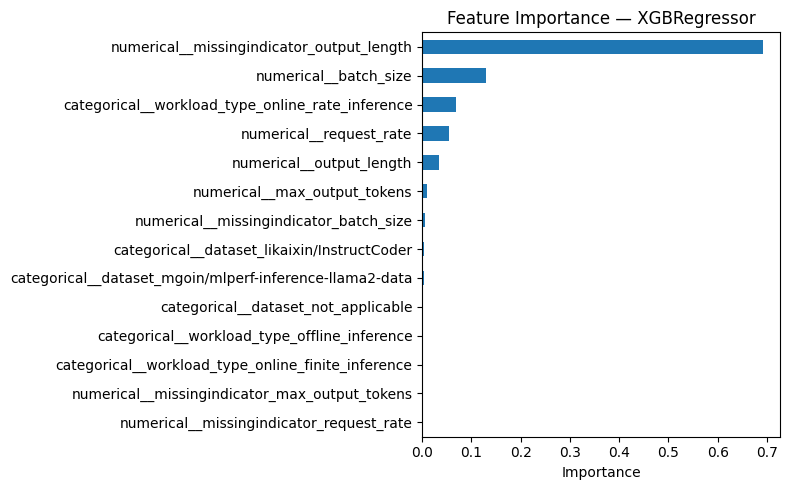

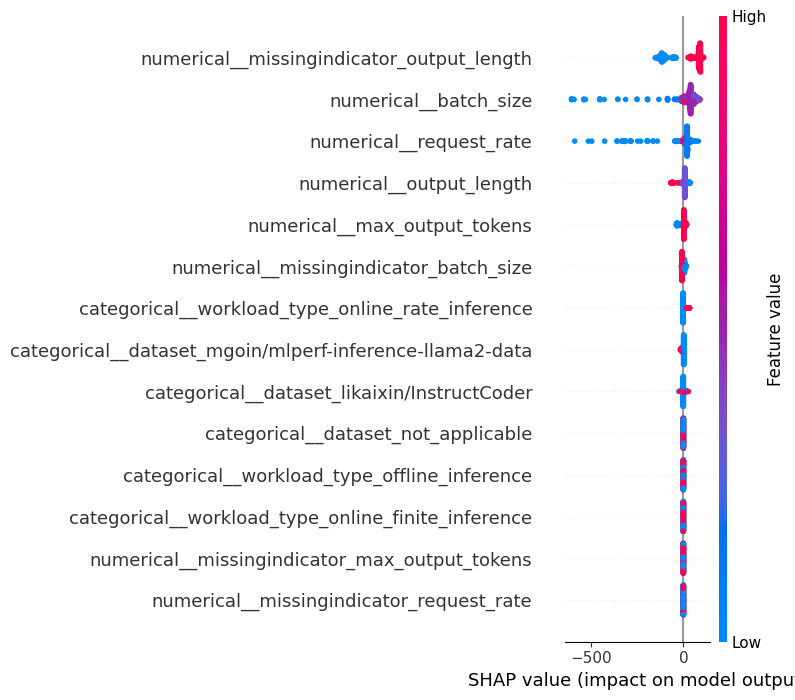

In [11]:
import matplotlib.pyplot as plt
# Feature importance is available for tree-based models.
if hasattr(best_model, "feature_importances_"):
    importance = (
        pd.Series(
            best_model.feature_importances_,
            index=X_train.columns,
        )
        .sort_values()
    )
    ax = importance.plot.barh(
        figsize=(8, 5),
        title=(
            f"Feature Importance — "
            f"{type(best_model).__name__}"
        ),
    )
    ax.set_xlabel("Importance")
    plt.tight_layout()
    plt.show()
else:
    print(
        "The selected model does not provide "
        "built in feature importances."
    )
# Attempt SHAP analysis for tree based models.
try:
    import shap
    if hasattr(best_model, "feature_importances_"):
        explainer = shap.TreeExplainer(best_model)
        shap_values = explainer.shap_values(
            X_test
        )
        shap.summary_plot(
            shap_values,
            X_test,
            feature_names=X_train.columns.tolist(),
            show=False,
        )
        plt.tight_layout()
        plt.show()
    else:
        print(
            "SHAP tree explanations are skipped "
            "because the selected model is not tree based."
        )
except ImportError:
    print(
        "SHAP is not installed. "
        "Install it with `pip install shap` if needed."
    )

## 3.11 Persist the Selected Model

The selected model is saved to Google Drive so that it persists across Colab sessions and can be reused in later deployment and inference workflows.

The saved artifact contains:

- The fitted model.
- The processed feature names used during training.
- The validation metrics used for model selection.

The preprocessing pipeline is stored separately as `preprocessor.joblib` by `02_Preprocessing.ipynb`.

In [12]:
import joblib
model_path = processed_dir / "best_model.joblib"
model_artifact = {
    "model": best_model,
    "feature_names": X_train.columns.tolist(),
    "validation_metrics": comparison.iloc[0].to_dict(),
}
joblib.dump(
    model_artifact,
    model_path,
)
print(
    f"Selected model saved to:\n{model_path}"
)
print(
    f"\nSelected model: {best_name}"
)

Selected model saved to:
/content/drive/MyDrive/data/processed/modeling/best_model.joblib

Selected model: XGBoost (tuned)
